Shortest distances from vertex 0:
  0 -> 0: 0.000
  0 -> 1: 6.153
  0 -> 2: 4.899
  0 -> 3: 5.521
  0 -> 4: 4.742
  0 -> 5: 6.516
  0 -> 6: 1.820
  0 -> 7: 4.273
  0 -> 8: 5.298
  0 -> 9: 4.669
Shortest path from 0 to 9: [0, 6, 9]
Total weight of the path: 4.669


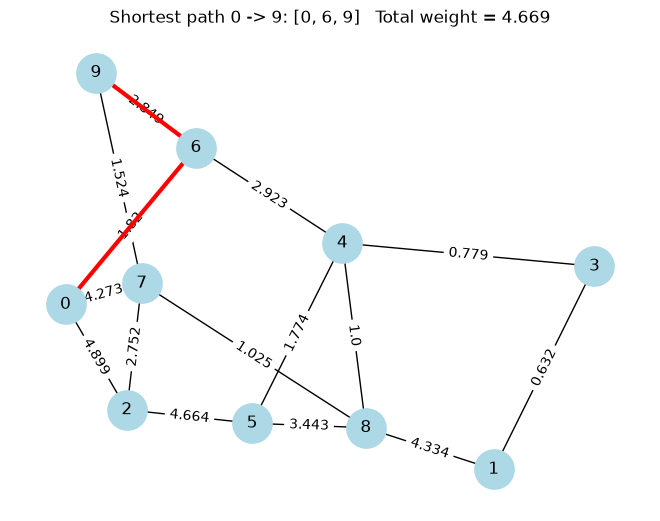

In [ ]:
import heapq #needed for heappush and heappop
from math import inf #needed for infinity
import networkx as nx #needed for developing the graphs
import random #randomizes the inputs for the graphs
# Dijkstra's algorithm
def dijkstra(graph, s):
    """
    Shortest paths from source s in a graph with non-negative edge weights.
    graph: dict mapping each vertex to a list of (neighbor, weight) pairs.
    s:     the source vertex.
    Returns (dist, parent):
      dist[v]   = length of the shortest path from s to v (inf if unreachable)
      parent[v] = vertex just before v on a shortest path (None for s / unreachable)
    """
    # Tentative distance for every vertex: 0 for s, infinity for the rest.
    dist = {v: inf for v in graph}
    parent = {v: None for v in graph}
    dist[s] = 0

    done = set()              # "finished" vertices, whose distance is final
    heap = [(0, s)]           # priority queue of (tentative distance, vertex)

    while heap:
        d, u = heapq.heappop(heap)    # closest vertex not yet finished
        if u in done:                 # stale entry: u was already finished
            continue
        done.add(u)                   # mark u as finished
        # Check whether going through u gives a shorter route to a neighbor.
        for v, w in graph[u]:
            if v not in done and d + w < dist[v]:
                dist[v] = d + w
                parent[v] = u
                heapq.heappush(heap, (dist[v], v))
    return dist, parent

def shortest_path(parent, s, t):
    """Rebuild the path from s to t using the parent pointers."""
    path = []
    v = t
    while v is not None:
        path.append(v)
        v = parent[v]
    path.reverse()
    return path if path and path[0] == s else []   # [] if t is unreachable

# Random graph code
def random_graph(n, m, max_weight=10):
    # Create an empty undirected graph
    G = nx.Graph()
    # Add n vertices
    G.add_nodes_from(range(n))
    # Generate all possible edges
    possible_edges = [
        (u, v)
        for u in range(n)
        for v in range(u + 1, n)
    ]
    # Make sure there aren't more edges than possible
    if m > len(possible_edges):
        raise ValueError("Too many edges for the given number of vertices.")
    # Randomly select m distinct edges
    edges = random.sample(possible_edges, m)
    # Assign each edge a random nonnegative weight
    for u, v in edges:
        weight = random.uniform(0, max_weight)
        G.add_edge(u, v, weight=weight)
    return G
G = random_graph(10, 15, 5) #Use this to generate the graph. The formula is (Number on nodes, Number of Edges, Max weight of all edges).

# Running Dijkstra on the random graph
# Convert the networkx graph into the adjacency-list dict that dijkstra() expects.
graph = {u: [(v, G[u][v]["weight"]) for v in G[u]] for u in G}

s, t = 0, 9   # source vertex and target vertex (change these as you like)
dist, parent = dijkstra(graph, s)
path = shortest_path(parent, s, t)

print(f"Shortest distances from vertex {s}:")
for v in sorted(dist):
    print(f"  {s} -> {v}: {dist[v]:.3f}")
if path:
    total_weight = dist[t]
    print(f"Shortest path from {s} to {t}: {path}")
    print(f"Total weight of the path: {total_weight:.3f}")
    title = f"Shortest path {s} -> {t}: {path}   Total weight = {total_weight:.3f}"
else:
    print(f"No path from {s} to {t} in this graph.")
    title = f"No path from {s} to {t} in this graph"

# Draw the graph (shortest path in red)
import matplotlib.pyplot as plt #We need this to draw the graph.
pos = nx.spring_layout(G) #This edits the layout for the graph.
nx.draw(G,pos,with_labels=True,node_color='lightblue',node_size=800)

# Display edge weights
edge_labels = nx.get_edge_attributes(G, 'weight') #You can shorten the weight values by using round(edge_labels, 2) to round the weights to 2 decimal places.
rounded_labels = {edge: round(weight, 3) for edge, weight in edge_labels.items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=rounded_labels)

# Highlight the shortest path found by Dijkstra's algorithm
nx.draw_networkx_edges(G, pos, edgelist=list(zip(path, path[1:])),edge_color="red", width=3)
plt.title(title)   # shows the path and its total weight above the graph

plt.show()